# In Silico FGF21 변이체 서열 설계 및 구조 일관성 분석 파이프라인
**Workflow:** 6M6E 코어 백본 전처리 → ProteinMPNN 기반 역접힘(Inverse Folding) 서열 샘플링 → 성숙형 전장(181 aa) 복원 → AlphaFold2 (ColabFold) 구조 재예측 및 Cα-RMSD / pLDDT 정량 비교

### 연구 배경 및 설계 범위 (Scope & Rationale)
야생형 성숙 FGF21(181 aa)은 생체 내 단백질 분해 및 자가 응집(aggregation) 경향으로 인해 약동학적 한계를 지닙니다. 선행 문헌에서는 코어 영역 내 **L98R** 치환을 통한 응집 억제 및 C-말단 **P171G, A180E (RGE)** 도입을 통한 수용체 활성·안정성 개선이 보고된 바 있습니다.

본 노트북은 NMR 실험 구조(**PDB: 6M6E**, 성숙형 잔기 14–141 코어 영역)를 백본 템플릿으로 사용하여, 특정 타겟 잔기(기본값: 성숙형 98번 위치)에서의 국소 서열 재설계 후보군을 탐색하고 예측된 3차원 구조의 접힘 일관성(fold consistency)을 평가하기 위해 구축된 연구용 파이프라인입니다.
- **잔기 고정 및 전장 복원:** 수용체(FGFR1c 및 β-Klotho) 결합에 관여하는 N-말단(1–13) 및 C-말단(142–181) 영역은 야생형(WT) 서열로 보존·복원하며, 코어 내 비표적 잔기(127개 위치)는 고정(fixed)합니다.
- **비교 대조군 설정:** 야생형(`FGF21_WT`), 문헌 기준 단일 변이(`FGF21_L98R`), Fc 비융합 3중 변이(`FGF21_RGE`: L98R/P171G/A180E)를 기준군으로 설정하고, ProteinMPNN(Soluble weights) 점수 상위 탐색 후보(`FGF21_D01`, `FGF21_D02`)와 구조 예측 지표를 대조합니다.
- **해석상 유의사항:** 본 파이프라인의 계산 지표(MPNN score, pLDDT, Cα-RMSD)는 백본 적합도 및 구조 예측 신뢰도를 나타내며, 실제 열안정성($T_m$), 용해도 또는 Fc-융합체(Efruxifermin 등)의 생물학적 활성을 직접 입증하지 않습니다.


## 1. 분석 환경 설정 및 ProteinMPNN 리포지토리 초기화
재현성 확보를 위해 고정된 커밋(`8907e66`)의 ProteinMPNN 저장소를 클론하고 작업 디렉터리를 구성합니다.


In [ ]:
#@title 1. 환경 및 의존성 설정
import os, sys, subprocess, importlib.util
from pathlib import Path

BASE = Path('/content') if Path('/content').exists() else Path.cwd()
PROJECT = BASE / 'FGF21_project'
PROJECT.mkdir(parents=True, exist_ok=True)
REPO = BASE / 'ProteinMPNN_fgf21'
COMMIT = '8907e6671bfbfc92303b5f79c4b5e6ce47cdef57'

os.environ['OMP_NUM_THREADS'] = '2'
os.environ['MKL_NUM_THREADS'] = '2'

missing = [p for p in ['numpy', 'pandas', 'matplotlib', 'torch'] if importlib.util.find_spec(p) is None]
if missing:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *missing], check=True)

if not (REPO / '.git').exists():
    REPO.mkdir(parents=True, exist_ok=True)
    subprocess.run(['git', 'init', '-q', str(REPO)], check=True)
    subprocess.run(['git', '-C', str(REPO), 'remote', 'add', 'origin', 'https://github.com/dauparas/ProteinMPNN.git'], check=True)
    subprocess.run(['git', '-C', str(REPO), 'fetch', '--depth', '1', 'origin', COMMIT], check=True)
    subprocess.run(['git', '-C', str(REPO), 'checkout', '-q', '--detach', 'FETCH_HEAD'], check=True)

actual_commit = subprocess.check_output(['git', '-C', str(REPO), 'rev-parse', 'HEAD'], text=True).strip()
assert actual_commit == COMMIT, 'Repository commit mismatch.'

import torch, numpy, pandas
print('ProteinMPNN commit:', actual_commit)
print('PyTorch:', torch.__version__, '| CUDA available:', torch.cuda.is_available())
print('Workspace:', PROJECT)


ProteinMPNN commit: 8907e6671bfbfc92303b5f79c4b5e6ce47cdef57
PyTorch: 2.11.0+cu130 | GPU 사용 가능: True
작업 폴더: /content/FGF21_project


## 2. 데이터 전처리, 마스킹 및 구조 정렬(Kabsch RMSD) 모듈 정의
서열 인덱싱 매핑(UniProt / 성숙형 / PDB / MPNN), 고정 잔기 JSONL 마스크 생성, 후보 서열 전장 복원 및 Kabsch 알고리즘 기반 Cα-RMSD 산출 함수를 정의합니다.


In [ ]:
#@title 2. 파이프라인 핵심 유틸리티 함수 정의
from pathlib import Path
import csv, hashlib, io, json, re, shutil, subprocess, sys, urllib.request, zipfile
import numpy as np
import pandas as pd

MPNN_COMMIT = '8907e6671bfbfc92303b5f79c4b5e6ce47cdef57'
AA3 = dict(zip(
    'ALA ARG ASN ASP CYS GLN GLU GLY HIS ILE LEU LYS MET PHE PRO SER THR TRP TYR VAL'.split(),
    'ARNDCQEGHILKMFPSTWYV'))
BETA_RANGES = [(17,22),(32,36),(40,44),(53,58),(62,67),(72,77),
               (81,85),(95,100),(104,109),(114,117),(136,139)]

def fetch(url, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    if not path.exists():
        request = urllib.request.Request(url, headers={'User-Agent':'FGF21-design-pipeline/1.0'})
        data = urllib.request.urlopen(request, timeout=90).read()
        path.write_bytes(data)
    return path

def fasta_records(text):
    records, title, seq = [], None, []
    for line in text.splitlines():
        line = line.strip()
        if not line:
            continue
        if line.startswith('>'):
            if title is not None:
                records.append((title, ''.join(seq)))
            title, seq = line[1:], []
        else:
            if title is None:
                raise ValueError('FASTA header가 없습니다.')
            seq.append(line)
    if title is not None:
        records.append((title, ''.join(seq)))
    return records

def atom_models(text):
    models, current = [], []
    for line in text.splitlines():
        if line.startswith('MODEL'):
            if current:
                models.append(current)
                current = []
        elif line.startswith('ENDMDL'):
            if current:
                models.append(current)
                current = []
        elif line.startswith('ATOM  ') and line[16] in (' ', 'A'):
            current.append(line)
    if current:
        models.append(current)
    if not models:
        raise ValueError('PDB에서 ATOM 좌표를 찾지 못했습니다.')
    return models

def ca_records(lines, chain='A'):
    result, seen = [], set()
    for line in lines:
        if line[21] != chain or line[12:16].strip() != 'CA':
            continue
        key = (line[21], int(line[22:26]), line[26])
        if key in seen:
            continue
        seen.add(key)
        result.append({
            'key':key, 'aa':AA3[line[17:20]],
            'xyz':[float(line[30:38]),float(line[38:46]),float(line[46:54])],
            'bfactor':float(line[60:66]),
        })
    return result

def prepare_reference(project):
    project = Path(project)
    ref = project/'reference'
    pdb = fetch('https://files.rcsb.org/download/6M6E.pdb', ref/'6M6E.pdb')
    fasta = fetch('https://rest.uniprot.org/uniprotkb/Q9NSA1.fasta', ref/'Q9NSA1.fasta')
    precursor = fasta_records(fasta.read_text())[0][1]
    assert len(precursor) == 209, 'UniProt 서열이 변경되었습니다. 209 aa 전구체인지 확인하세요.'
    mature = precursor[28:]
    assert len(mature) == 181 and mature[97]=='L' and mature[170]=='P' and mature[179]=='A'
    models = atom_models(pdb.read_text())
    first = [l for l in models[0] if l[21]=='A']
    records = ca_records(first)
    core = ''.join(r['aa'] for r in records)
    assert len(core)==128 and core==mature[13:141], '6M6E 코어와 성숙형 14–141번이 일치하지 않습니다.'
    ref.joinpath('6M6E_model1_original.pdb').write_text('\n'.join(first)+'\nEND\n')
    mapping = pd.DataFrame([
        {'mpnn_position':i, 'pdb_author_position':r['key'][1],
         'pdb_insertion_code':r['key'][2].strip(), 'mature_position':i+13,
         'uniprot_position':i+41, 'aa':r['aa']}
        for i,r in enumerate(records,1)])
    mapping.to_csv(project/'residue_mapping.csv',index=False)
    key_to_index={r['key']:i for i,r in enumerate(records,1)}
    renumbered=[]
    for line in first:
        key=(line[21],int(line[22:26]),line[26])
        renumbered.append(line[:22]+f'{key_to_index[key]:4d}'+' '+line[27:])
    target=project/'mpnn_input'
    target.mkdir(exist_ok=True)
    target.joinpath('fgf21_core.pdb').write_text('\n'.join(renumbered)+'\nEND\n')
    return mature, core, mapping

def make_masks(project, core, design_mature, exclude_native=True):
    # Renumber core PDB residues to 1..128 for ProteinMPNN indexing
    design_mature=sorted(set(int(p) for p in design_mature))
    assert design_mature and all(14<=p<=141 for p in design_mature)
    assert len(design_mature)<=8, '동시 설계 타겟 위치는 최대 8개로 제한됩니다.'
    # Generate fixed position and native AA omission masks
    design_mpnn=[p-13 for p in design_mature]
    fixed=[i for i in range(1,129) if i not in design_mpnn]
    params=Path(project)/'mpnn_parameters'
    params.mkdir(exist_ok=True)
    (params/'fixed.jsonl').write_text(json.dumps({'fgf21_core':{'A':fixed}})+'\n')
    (params/'chains.jsonl').write_text(json.dumps({'fgf21_core':[['A'],[]]})+'\n')
    omitted=[[[i],core[i-1]] for i in design_mpnn] if exclude_native else []
    (params/'omit_native.jsonl').write_text(json.dumps({'fgf21_core':{'A':omitted}})+'\n')
    return design_mpnn, fixed

def run_mpnn(project, repo, temperatures, per_temperature, seed):
    project,repo=Path(project),Path(repo)
    params=project/'mpnn_parameters'
    parsed=params/'parsed.jsonl'
    subprocess.run([sys.executable,str(repo/'helper_scripts/parse_multiple_chains.py'),
        '--input_path',str(project/'mpnn_input'),'--output_path',str(parsed)],check=True)
    parsed_items=[json.loads(x) for x in parsed.read_text().splitlines()]
    assert len(parsed_items)==1 and len(parsed_items[0]['seq_chain_A'])==128
    args=[sys.executable,str(repo/'protein_mpnn_run.py'),
          '--jsonl_path',str(parsed),'--chain_id_jsonl',str(params/'chains.jsonl'),
          '--fixed_positions_jsonl',str(params/'fixed.jsonl'),
          '--omit_AA_jsonl',str(params/'omit_native.jsonl'),
          '--out_folder',str(project/'mpnn_output'),
          '--num_seq_per_target',str(per_temperature),
          '--sampling_temp',' '.join(map(str,temperatures)),
          '--seed',str(seed),'--batch_size','1',
          '--use_soluble_model','--model_name','v_48_020']
    log=subprocess.run(args,cwd=repo,check=True,text=True,stdout=subprocess.PIPE,stderr=subprocess.STDOUT)
    (project/'mpnn_run.log').write_text(log.stdout)
    print(log.stdout[-2200:])
    return args

def make_variants(project, mature, core, design_mature, settings, max_new=2):
    project=Path(project)
    records=fasta_records((project/'mpnn_output/seqs/fgf21_core.fa').read_text())
    samples=[]
    for header,seq in records:
        if 'sample=' not in header:
            continue
        assert len(seq)==128 and set(seq)<=set(AA3.values())
        changed=[i+14 for i,(a,b) in enumerate(zip(core,seq)) if a!=b]
        assert set(changed)<=set(design_mature), '고정된 위치에 변이가 생겼습니다.'
        full=mature[:13]+seq+mature[141:]
        assert len(full)==181 and full[:13]==mature[:13] and full[141:]==mature[141:]
        fields=dict(re.findall(r'(\w+)=([^, ]+)',header))
        mutations=','.join(f'{mature[p-1]}{p}{full[p-1]}' for p in changed) or 'WT'
        samples.append({'mutations':mutations,'sequence':full,'core_sequence':seq,
                        'mpnn_score':float(fields['score']),
                        'temperature':float(fields['T']), 'sample':int(fields['sample'])})
    raw=pd.DataFrame(samples)
    assert len(raw)>0, '생성 서열이 없습니다. mpnn_run.log를 확인하세요.'
    raw.to_csv(project/'all_mpnn_samples.csv',index=False)
    unique=raw.sort_values('mpnn_score').drop_duplicates('sequence').reset_index(drop=True)
    unique.to_csv(project/'unique_mpnn_candidates.csv',index=False)
    l98r=mature[:97]+'R'+mature[98:]
    rge=list(l98r);rge[170]='G';rge[179]='E';rge=''.join(rge)
    variants=[
        {'id':'FGF21_WT','mutations':'WT','sequence':mature,'role':'reference'},
        {'id':'FGF21_L98R','mutations':'L98R','sequence':l98r,'role':'literature_reference'},
        {'id':'FGF21_RGE','mutations':'L98R,P171G,A180E','sequence':rge,'role':'Fc_free_reference'},
    ]
    extra=unique[~unique.sequence.isin([x['sequence'] for x in variants])].head(max_new)
    for i,(_,row) in enumerate(extra.iterrows(),1):
        variants.append({'id':f'FGF21_D{i:02d}','mutations':row.mutations,
                         'sequence':row.sequence,'role':'exploratory_candidate',
                         'mpnn_score':float(row.mpnn_score)})
    inputs=project/'colabfold_inputs'
    inputs.mkdir(exist_ok=True)
    # Clean existing FASTA inputs in workspace
    for old in inputs.glob('FGF21_*.fasta'):
        old.unlink()
    for v in variants:
        (inputs/(v['id']+'.fasta')).write_text('>'+v['id']+'\n'+v['sequence']+'\n')
    pd.DataFrame(variants)[['id','sequence']].to_csv(project/'colabfold_inputs.csv',index=False)
    (project/'colabfold_paste.txt').write_text('\n\n'.join(
        f"jobname: {v['id']}\nmutations: {v['mutations']}\nquery_sequence:\n{v['sequence']}" for v in variants))
    manifest={'schema_version':1,'created_utc':pd.Timestamp.now(tz='UTC').isoformat(),
              'scope':'FGF21 mature monomer; no Fc; exploratory sequence sampling, not stability validation',
              'mpnn_commit':MPNN_COMMIT,'settings':settings,
              'variants':variants,'mature_sequence':mature,
              'reference':{'pdb':'6M6E','model':1,'core_mature_range':[14,141],
                           'uniprot':'Q9NSA1','signal_peptide_length':28},
              'reference_sha256':{p.name:hashlib.sha256(p.read_bytes()).hexdigest()
                   for p in [project/'reference/6M6E.pdb',project/'reference/Q9NSA1.fasta']}}
    (project/'manifest.json').write_text(json.dumps(manifest,ensure_ascii=False,indent=2))
    print(f'샘플 {len(raw)}개 → 서로 다른 서열 {len(unique)}개 → ColabFold 입력 {len(variants)}개')
    if len(extra)<max_new:
        print('새 후보 수가 적습니다. 중복을 복제하지 않았으며, 생성되지 않은 후보를 만들지 않았습니다.')
    return pd.DataFrame(variants),manifest

def bundle_project(project):
    project=Path(project)
    output=project.parent/'FGF21_design_bundle.zip'
    with zipfile.ZipFile(output,'w',zipfile.ZIP_DEFLATED) as z:
        for p in sorted(project.rglob('*')):
            if p.is_file() and not any(x in p.parts for x in ['analysis','uploads']):
                z.write(p,p.relative_to(project))
    return output

def safe_unzip(data, destination):
    destination=Path(destination).resolve()
    destination.mkdir(parents=True,exist_ok=True)
    with zipfile.ZipFile(io.BytesIO(data)) as z:
        if sum(x.file_size for x in z.infolist())>500_000_000:
            raise ValueError('압축 해제 크기가 500 MB를 넘습니다. 필요한 결과 ZIP만 업로드하세요.')
        for item in z.infolist():
            target=(destination/item.filename).resolve()
            if not target.is_relative_to(destination):
                raise ValueError('허용하지 않는 ZIP 경로입니다.')
        z.extractall(destination)

def kabsch(mobile, target):
    mobile,target=np.asarray(mobile,float),np.asarray(target,float)
    assert mobile.shape==target.shape and mobile.shape[1]==3
    a,b=mobile.mean(0),target.mean(0)
    u,_,vt=np.linalg.svd((mobile-a).T@(target-b))
    correction=np.eye(3);correction[-1,-1]=np.sign(np.linalg.det(u@vt))
    rotation=u@correction@vt
    shift=b-a@rotation
    rmsd=float(np.sqrt(np.mean(np.sum((mobile@rotation+shift-target)**2,axis=1))))
    return rmsd,rotation,shift

def aligned_pdb(lines, rotation, shift):
    output=[]
    for line in lines:
        xyz=np.array([float(line[30:38]),float(line[38:46]),float(line[46:54])])@rotation+shift
        output.append(line[:30]+f'{xyz[0]:8.3f}{xyz[1]:8.3f}{xyz[2]:8.3f}'+line[54:])
    return '\n'.join(output)+'\nEND\n'

def analyze_predictions(project, uploads_dir):
    project,uploads_dir=Path(project),Path(uploads_dir)
    manifests=([project/'manifest.json'] if (project/'manifest.json').exists() else [])
    manifests+=list(uploads_dir.rglob('manifest.json'))
    if not manifests:
        raise ValueError('FGF21_design_bundle.zip도 함께 업로드하세요. 설계 서열 목록이 필요합니다.')
    manifest=json.loads(manifests[0].read_text())
    for other in manifests[1:]:
        if json.loads(other.read_text()).get('variants')!=manifest['variants']:
            raise ValueError('서로 다른 설계 실행의 manifest가 섞였습니다. 해당 실행의 ZIP만 사용하세요.')
    references=([project/'reference/6M6E.pdb'] if (project/'reference/6M6E.pdb').exists() else [])
    references+=list(uploads_dir.rglob('6M6E.pdb'))
    if not references:
        raise ValueError('6M6E 기준 구조가 없습니다. FGF21_design_bundle.zip을 업로드하세요.')
    ref_models=atom_models(references[0].read_text())
    ref_xyz=np.array([r['xyz'] for r in ca_records(ref_models[0])])
    assert ref_xyz.shape==(128,3)
    beta_idx=np.array([p-14 for lo,hi in BETA_RANGES for p in range(lo,hi+1)])
    by_seq={v['sequence']:v for v in manifest['variants']}
    rows,raw,seen=[],{},set()
    for pdb in sorted(uploads_dir.rglob('*unrelaxed_rank_*.pdb')):
        digest=hashlib.sha256(pdb.read_bytes()).hexdigest()
        if digest in seen:
            continue
        seen.add(digest)
        lines=atom_models(pdb.read_text())[0]
        cas=ca_records(lines)
        seq=''.join(r['aa'] for r in cas)
        if seq not in by_seq:
            raise ValueError(f'예상 서열과 다른 결과입니다: {pdb.name}. 입력 서열과 설계 ZIP을 확인하세요.')
        assert len(cas)==181
        assert [r['key'][1] for r in cas]==list(range(1,182)), '예측 PDB 번호가 1–181이 아닙니다.'
        assert set(l[21] for l in lines)=={'A'}, '단일 체인 결과가 아닙니다.'
        xyz=np.array([r['xyz'] for r in cas]); core_xyz=xyz[13:141]
        confidence=np.array([r['bfactor'] for r in cas])
        assert np.all((confidence>=0)&(confidence<=100))
        rank=int(re.search(r'_rank_(\d+)',pdb.name).group(1))
        modelmatch=re.search(r'(model_\d+_seed_\d+)',pdb.name)
        if not modelmatch:
            raise ValueError(f'모델·seed 표기를 읽을 수 없습니다: {pdb.name}')
        modelkey=modelmatch.group(1)
        v=by_seq[seq]; key=(v['id'],modelkey)
        if key in raw:
            raise ValueError(f'{key}의 중복 실행 결과가 섞였습니다. 각 서열당 한 실행의 ZIP만 사용하세요.')
        rmsd,rotation,shift=kabsch(core_xyz,ref_xyz)
        rows.append({'id':v['id'],'mutations':v['mutations'],'rank':rank,
                     'model_seed':modelkey,'full_mean_pLDDT':confidence.mean(),
                     'core_mean_pLDDT':confidence[13:141].mean(),
                     'core_CA_RMSD_vs_NMR1_A':rmsd,
                     'beta_CA_RMSD_vs_NMR1_A':kabsch(core_xyz[beta_idx],ref_xyz[beta_idx])[0],
                     'source_file':pdb.name})
        raw[key]={'xyz':core_xyz,'plddt':confidence,'rank':rank,
                  'aligned':aligned_pdb(lines,rotation,shift)}
    if not rows:
        raise ValueError('ColabFold 결과의 unrelaxed_rank_*.pdb를 찾지 못했습니다. .result.zip을 올려주세요.')
    for row in rows:
        wt=raw.get(('FGF21_WT',row['model_seed']))
        item=raw[(row['id'],row['model_seed'])]
        row['core_CA_RMSD_vs_WT_same_model_A']=kabsch(item['xyz'],wt['xyz'])[0] if wt else np.nan
        row['delta_core_pLDDT_vs_WT_same_model']=float(item['plddt'][13:141].mean()-wt['plddt'][13:141].mean()) if wt else np.nan
    details=pd.DataFrame(rows).sort_values(['id','rank'])
    output=project/'analysis'
    output.mkdir(parents=True,exist_ok=True)
    details.to_csv(output/'model_metrics.csv',index=False)
    summary=details.groupby(['id','mutations']).agg(
        n_models=('rank','count'), core_pLDDT_mean=('core_mean_pLDDT','mean'),
        core_pLDDT_min=('core_mean_pLDDT','min'),core_pLDDT_max=('core_mean_pLDDT','max'),
        core_RMSD_NMR1_mean_A=('core_CA_RMSD_vs_NMR1_A','mean'),
        beta_RMSD_NMR1_mean_A=('beta_CA_RMSD_vs_NMR1_A','mean'),
        core_RMSD_WT_matched_mean_A=('core_CA_RMSD_vs_WT_same_model_A','mean'),
        delta_core_pLDDT_WT_matched_mean=('delta_core_pLDDT_vs_WT_same_model','mean')
    ).reset_index()
    summary.to_csv(output/'summary.csv',index=False)
    expected={v['id'] for v in manifest['variants']}
    present=set(details.id)
    if expected-present:
        print('아직 업로드되지 않은 서열:',', '.join(sorted(expected-present)))
    if any(summary.n_models!=5):
        print('참고: 일부 서열은 5개 모델이 아닙니다. 실행 완료 여부와 동일 설정을 확인하세요.')
    if 'FGF21_WT' not in present:
        print('WT 결과가 없어 WT 대비 차이는 빈 값입니다.')
    (output/'reference_NMR1.pdb').write_text('\n'.join(ref_models[0])+'\nEND\n')
    pymol=['load reference_NMR1.pdb, NMR1','hide everything','show cartoon','color gray70, NMR1']
    colors=['cyan','orange','green','magenta','blue']
    import matplotlib.pyplot as plt
    fig,ax=plt.subplots(figsize=(10,4))
    for n,v in enumerate(manifest['variants']):
        selected=[r for (ident,_),r in raw.items() if ident==v['id'] and r['rank']==1]
        if not selected:
            continue
        item=selected[0]
        filename=v['id']+'_rank1_aligned.pdb'
        (output/filename).write_text(item['aligned'])
        pymol.extend([f'load {filename}, {v["id"]}',f'color {colors[n%len(colors)]}, {v["id"]}'])
        ax.plot(np.arange(1,182),item['plddt'],label=v['id'],lw=1.5)
    ax.axvspan(14,141,color='grey',alpha=.08,label='Core 14–141')
    ax.set(xlabel='Mature FGF21 residue',ylabel='pLDDT (confidence)',ylim=(0,100),
           title='Residue-level pLDDT Profiles (Rank-1 Models)')
    ax.legend(fontsize=8,ncol=2);fig.tight_layout()
    fig.savefig(output/'pLDDT_profiles.png',dpi=180)
    plt.show();plt.close(fig)
    pymol.extend(['show cartoon','bg_color white','zoom all'])
    (output/'view_aligned.pml').write_text('\n'.join(pymol)+'\n')
    notes=('All RMSDs use explicit matched C-alpha coordinates and Kabsch fitting, without outlier rejection.\n'
           'Core = mature residues 14–141; beta ranges are predefined from Zhu et al. 2021.\n'
           'WT comparisons pair the same AlphaFold model number and seed, not prediction rank.\n'
           'pLDDT is model confidence, not Tm, solubility, binding affinity, or measured aggregation.\n'
           'Five models are not five independent experimental replicates; their range is not a confidence interval.\n'
           'Rank-1 PDB coordinates were transformed onto NMR model 1 for visualization.\n'
           'Open view_aligned.pml with the working directory set to this extracted folder.\n'
           'Archive each original ColabFold result ZIP, including its MSA, config and log.\n')
    (output/'README_results.txt').write_text(notes)
    (output/'design_manifest.json').write_text(json.dumps(manifest,ensure_ascii=False,indent=2))
    archive=Path(shutil.make_archive(str(project.parent/'FGF21_analysis'),'zip',output))
    return details,summary,archive


## 3. 참조 구조(6M6E) 및 서열(Q9NSA1) 로드·인덱싱 매핑
- **UniProt Q9NSA1:** 전구체(209 aa)에서 N-말단 신호 펩타이드(28 aa)를 제외한 성숙형(Mature, 181 aa) 서열 추출.
- **PDB 6M6E:** 성숙형 잔기 14–141에 해당하는 코어 구조(128 aa, NMR Ensemble Model 1) 추출 및 ProteinMPNN 입력용 재넘버링(1–128).
- **타겟 잔기 인덱스 매핑:** 성숙형 `L98` = 6M6E Author `98` = MPNN 코어 입력 `85` = UniProt 전구체 `126`.


In [ ]:
#@title 3. 참조 데이터 로드 및 잔기 인덱스 매핑 확인
mature, core, mapping = prepare_reference(PROJECT)
print('성숙형 길이:', len(mature), '| 코어 길이:', len(core))
display(mapping[mapping.mature_position.between(95, 101)])
print('전체 매핑 테이블 저장 경로: residue_mapping.csv')


성숙형 길이: 181 | 코어 길이: 128


,mpnn_position,pdb_author_position,pdb_insertion_code,mature_position,uniprot_position,aa
81,82,95,,95,123,F
82,83,96,,96,124,R
83,84,97,,97,125,E
84,85,98,,98,126,L
85,86,99,,99,127,L
86,87,100,,100,128,L
87,88,101,,101,129,E


전체 대응표: residue_mapping.csv


## 4. 타겟 잔기 마스킹 및 샘플링 하이퍼파라미터 설정
코어 128개 잔기 중 성숙형 98번 위치(`design_mature = 98`, MPNN 인덱스 `85`)만 재설계를 허용하고 나머지 127개 잔기를 고정합니다.

| 파라미터 | 설정값 | 설명 |
|---|---:|---|
| `design_mature_text` | `98` | 재설계 타겟 위치 (성숙형 번호 기준, 코어 내 14–141 범위) |
| `temperatures_text` | `0.1 0.2` | ProteinMPNN 샘플링 온도 ($T$). 보수적 서열 탐색을 위해 저온 영역 설정 |
| `samples_per_temperature` | `10` | 온도 조건당 생성할 시퀀스 샘플 수 (총 20개 샘플링) |
| `exclude_native` | `True` | 타겟 위치에서 야생형 아미노산(L)을 제외하고 대체 변이 후보만 샘플링 |
| `number_new_candidates` | `2` | 대조군 3종(WT, L98R, RGE) 외 구조 예측에 포함할 상위 MPNN 탐색 후보 수 |
| `weights` | `soluble` | 수용성 단백질 학습 가중치(`v_48_020`, `--use_soluble_model`) 적용 |


In [ ]:
#@title 4. 마스킹 및 샘플링 파라미터 구성
design_mature_text = '98' #@param {type:'string'}
temperatures_text = '0.1 0.2' #@param {type:'string'}
samples_per_temperature = 10 #@param {type:'integer'}
exclude_native = True #@param {type:'boolean'}
number_new_candidates = 2 #@param {type:'integer'}
seed = 20261017 #@param {type:'integer'}

design_mature = [int(x) for x in design_mature_text.replace(',', ' ').split()]
temperatures = [float(x) for x in temperatures_text.replace(',', ' ').split()]
assert all(0 < t <= 1 for t in temperatures)
assert 1 <= samples_per_temperature <= 50 and 0 <= number_new_candidates <= 5

design_mpnn, fixed = make_masks(PROJECT, core, design_mature, exclude_native)
settings = {
    'design_mature': design_mature, 'design_mpnn': design_mpnn,
    'exclude_native': exclude_native, 'temperatures': temperatures,
    'per_temperature': samples_per_temperature, 'seed': seed,
    'model_name': 'v_48_020', 'weights': 'soluble',
    'torch_version': torch.__version__, 'numpy_version': numpy.__version__,
    'pandas_version': pandas.__version__
}
print('성숙형 설계 위치:', design_mature, '→ MPNN 위치:', design_mpnn)
print('고정 위치 수:', len(fixed), '| 생성 샘플 수:', samples_per_temperature * len(temperatures))


성숙형 설계 위치: [98] → MPNN 위치: [85]
고정 위치 수: 127 | 생성 샘플 수: 20


## 5. ProteinMPNN 서열 디자인 실행
고정 백본(`fgf21_core.pdb`) 및 잔기 마스크 설정을 기반으로 역접힘 서열 샘플링을 수행합니다.


In [ ]:
#@title 5. ProteinMPNN 실행
command_used = run_mpnn(PROJECT, REPO, temperatures, samples_per_temperature, seed)
settings['command'] = command_used
print('완료. 원본 샘플: mpnn_output/seqs/fgf21_core.fa')


Using ProteinMPNN trained on soluble proteins only!
----------------------------------------
pssm_jsonl is NOT loaded
----------------------------------------
bias_AA_jsonl is NOT loaded
----------------------------------------
tied_positions_jsonl is NOT loaded
----------------------------------------
bias by residue dictionary is not loaded, or not provided
----------------------------------------
discarded {'bad_chars': 0, 'too_long': 0, 'bad_seq_length': 0}
----------------------------------------
Number of edges: 48
Training noise level: 0.2A
Generating sequences for: fgf21_core
20 sequences of length 128 generated in 11.004 seconds

완료. 원본 샘플: mpnn_output/seqs/fgf21_core.fa


## 6. 후보 서열 중복 제거 및 전장(181 aa) 서열 복원
1. **무결성 검증 및 중복 제거:** 고정 잔기(127개) 보존 여부를 검증하고 동일 서열 샘플을 병합하여 `mpnn_score`(negative log-likelihood) 기준 오름차순 정렬합니다.
2. **성숙형 전장 복원:** 설계된 128 aa 코어 서열 양단에 야생형 N-말단(1–13) 및 C-말단(142–181) 서열을 결합하여 181 aa 전장 서열을 구성합니다.
3. **비교 패널 구축:**
   - `FGF21_WT`: 야생형 성숙 FGF21 (Reference)
   - `FGF21_L98R`: 문헌 보고 항응집 단일 변이 (Literature reference; Hecht et al., 2012)
   - `FGF21_RGE`: C-말단 안정화 변이가 추가된 Fc 비융합 변이 (`L98R, P171G, A180E`)
   - `FGF21_D01` (`L98I`), `FGF21_D02` (`L98V`): 본 실행에서 도출된 소수성 베타-분지(β-branched) 치환 탐색 후보


In [ ]:
#@title 6. 비교 대상 변이체 패널 생성 및 FASTA 출력
variants, manifest = make_variants(PROJECT, mature, core, design_mature, settings, number_new_candidates)
display(variants.drop(columns=['sequence']))
print((PROJECT / 'colabfold_paste.txt').read_text())


샘플 20개 → 서로 다른 서열 2개 → ColabFold 입력 5개


,id,mutations,role,mpnn_score
0,FGF21_WT,WT,reference,NaN
1,FGF21_L98R,L98R,literature_reference,NaN
2,FGF21_RGE,"L98R,P171G,A180E",Fc_free_reference,NaN
3,FGF21_D01,L98I,exploratory_candidate,1.1696
4,FGF21_D02,L98V,exploratory_candidate,1.6682


jobname: FGF21_WT
mutations: WT
query_sequence:
HPIPDSSPLLQFGGQVRQRYLYTDDAQQTEAHLEIREDGTVGGAADQSPESLLQLKALKPGVIQILGVKTSRFLCQRPDGALYGSLHFDPEACSFRELLLEDGYNVYQSEAHGLPLHLPGNKSPHRDPAPRGPARFLPLPGLPPALPEPPGILAPQPPDVGSSDPLSMVGPSQGRSPSYAS

jobname: FGF21_L98R
mutations: L98R
query_sequence:
HPIPDSSPLLQFGGQVRQRYLYTDDAQQTEAHLEIREDGTVGGAADQSPESLLQLKALKPGVIQILGVKTSRFLCQRPDGALYGSLHFDPEACSFRERLLEDGYNVYQSEAHGLPLHLPGNKSPHRDPAPRGPARFLPLPGLPPALPEPPGILAPQPPDVGSSDPLSMVGPSQGRSPSYAS

jobname: FGF21_RGE
mutations: L98R,P171G,A180E
query_sequence:
HPIPDSSPLLQFGGQVRQRYLYTDDAQQTEAHLEIREDGTVGGAADQSPESLLQLKALKPGVIQILGVKTSRFLCQRPDGALYGSLHFDPEACSFRERLLEDGYNVYQSEAHGLPLHLPGNKSPHRDPAPRGPARFLPLPGLPPALPEPPGILAPQPPDVGSSDPLSMVGGSQGRSPSYES

jobname: FGF21_D01
mutations: L98I
query_sequence:
HPIPDSSPLLQFGGQVRQRYLYTDDAQQTEAHLEIREDGTVGGAADQSPESLLQLKALKPGVIQILGVKTSRFLCQRPDGALYGSLHFDPEACSFREILLEDGYNVYQSEAHGLPLHLPGNKSPHRDPAPRGPARFLPLPGLPPALPEPPGILAPQPPDVGSSDPLSMVGPSQGRSPSYAS

jobname: FGF21_D02
mutations: L98V
query_sequence:
HPI

## 7. 설계 아티팩트 패키징 (`FGF21_design_bundle.zip`)
참조 PDB, 잔기 매핑 테이블, MPNN 샘플링 로그, 후보 서열 FASTA 및 메타데이터(`manifest.json`)를 단일 아카이브로 압축하여 저장합니다.


In [ ]:
#@title 7. 설계 번들 아카이브 생성 및 다운로드
design_zip = bundle_project(PROJECT)
print(design_zip)
try:
    from google.colab import files
    files.download(str(design_zip))
except ImportError:
    print('Archive saved locally at:', design_zip)


/content/FGF21_design_bundle.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 8. AlphaFold2 (ColabFold) 구조 예측 프로토콜
선정된 5종의 전장 서열(`FGF21_WT`, `FGF21_L98R`, `FGF21_RGE`, `FGF21_D01`, `FGF21_D02`)에 대해 [ColabFold AlphaFold2](https://colab.research.google.com/github/sokrypton/ColabFold/blob/main/AlphaFold2.ipynb)에서 동일한 파라미터 조건으로 구조 예측을 수행합니다.

### 예측 파라미터 사양 (Prediction Configuration)
내재적 서열 접힘 경향을 평가하기 위해 외부 구조 템플릿(`template_mode: none`)을 배제하고 MSA 기반 예측을 수행합니다.

| 파라미터 | 설정값 | 비고 |
|---|---|---|
| `msa_mode` | `mmseqs2_uniref_env` | UniRef + Environmental MSA 검색 |
| `model_type` | `alphafold2_ptm` | 5개 AF2 모델 앙상블 예측 |
| `num_recycles` | `3` | 조기 종료 비활성화 (`recycle_early_stop_tolerance = 0.0`) |
| `template_mode` | `none` | 6M6E 등 실험 구조 템플릿 편향 배제 |
| `num_relax` | `0` | Unrelaxed 구조 좌표 및 B-factor(pLDDT) 직접 추출 |
| `num_seeds` | `1` | 서열당 5개 모델(`model_1`~`model_5`) 생성 |


## 9. ColabFold 예측 결과 아카이브 로드
각 변이체별 ColabFold 예측 결과(`*.result.zip`) 및 설계 매니페스트(`FGF21_design_bundle.zip`)를 워크스페이스에 로드하고 무결성을 검증합니다.


In [ ]:
#@title 9. 결과 ZIP 업로드 및 압축 해제
from google.colab import files

UPLOADS = PROJECT / 'uploads'
if UPLOADS.exists():
    shutil.rmtree(UPLOADS)
if (PROJECT / 'analysis').exists():
    shutil.rmtree(PROJECT / 'analysis')
UPLOADS.mkdir(parents=True)

uploaded = files.upload()
for n, (name, data) in enumerate(uploaded.items()):
    if not name.lower().endswith('.zip'):
        raise ValueError('ZIP format required: ' + name)
    safe_unzip(data, UPLOADS / f'archive_{n:02d}')
print('업로드 완료:', len(uploaded), '개 ZIP')


Saving FGF21_D02_39d7e.result.zip to FGF21_D02_39d7e.result.zip
Saving FGF21_D01_15ff4.result.zip to FGF21_D01_15ff4.result.zip
Saving FGF21_RGE_c2a31.result.zip to FGF21_RGE_c2a31.result.zip
Saving FGF21_L98R_acde5.result.zip to FGF21_L98R_acde5.result.zip
Saving FGF21_design_bundle.zip to FGF21_design_bundle.zip
Saving FGF21_WT_b7606.zip to FGF21_WT_b7606.zip
업로드 완료: 6 개 ZIP


## 10. 구조 신뢰도(pLDDT) 및 백본 편차(Cα-RMSD) 정량 분석
예측된 5개 모델의 Unrelaxed PDB로부터 잔기별 pLDDT와 Cα 좌표를 추출하여 정량 비교를 수행합니다.
- **Core pLDDT:** 성숙형 코어 영역(잔기 14–141, 128 aa)의 평균 예측 신뢰도.
- **Core Cα-RMSD vs. NMR1:** 6M6E Model 1 코어 Cα 좌표(128개) 대비 Kabsch 최적 중첩(outlier 제거 없음) 후 산출한 RMSD.
- **β-Strand Cα-RMSD vs. NMR1:** 유연한 루프(loop)에 의한 편차를 분리하기 위해, β-트레포일(β-trefoil) 코어를 구성하는 11개 β-strand 잔기 구간(Zhu et al., 2021 정의)만 독립적으로 Kabsch 정렬한 RMSD.
- **WT-Matched ΔpLDDT & RMSD:** 예측 순위(rank)가 아닌 **동일한 AlphaFold 모델 번호 및 시드(`model_X_seed_000`)** 간 1:1 매칭 비교를 통해 변이 도입에 따른 순수 구조 변화량 산출.


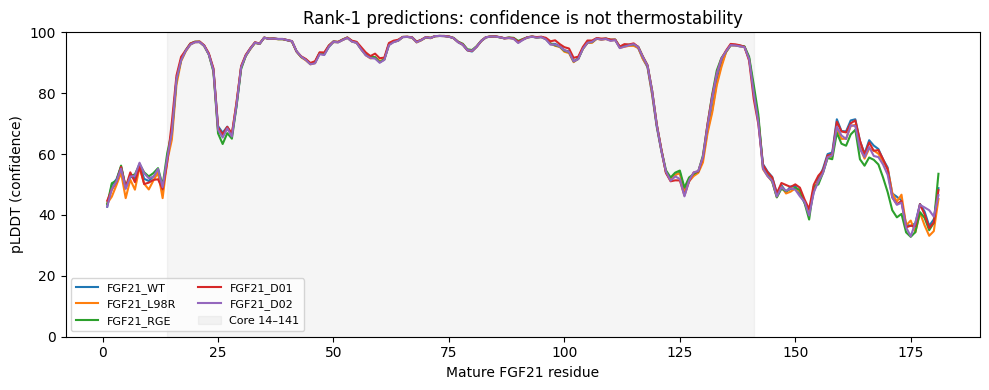

,id,mutations,n_models,core_pLDDT_mean,core_pLDDT_min,core_pLDDT_max,core_RMSD_NMR1_mean_A,beta_RMSD_NMR1_mean_A,core_RMSD_WT_matched_mean_A,delta_core_pLDDT_WT_matched_mean
0,FGF21_D01,L98I,5,88.786,87.447,90.070,2.579,0.767,0.179,-0.018
1,FGF21_D02,L98V,5,88.639,87.112,89.781,2.605,0.769,0.156,-0.165
2,FGF21_L98R,L98R,5,88.686,87.685,89.631,2.594,0.766,0.430,-0.118
3,FGF21_RGE,"L98R,P171G,A180E",5,88.820,87.325,90.084,2.628,0.762,0.440,0.016
4,FGF21_WT,WT,5,88.804,87.363,89.761,2.603,0.772,0.000,0.000


모델별 상세값: model_metrics.csv
요약: summary.csv | 그림: pLDDT_profiles.png
PyMOL용 정렬 구조와 view_aligned.pml도 포함됩니다.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
#@title 10. 정량 지표 산출, 프로파일 시각화 및 분석 결과 패키징
details, summary, analysis_zip = analyze_predictions(PROJECT, UPLOADS)
display(summary.round(3))
print('모델별 상세값: model_metrics.csv')
print('요약: summary.csv | 그림: pLDDT_profiles.png')
print('PyMOL용 정렬 구조와 view_aligned.pml도 포함됩니다.')
from google.colab import files
files.download(str(analysis_zip))


## 11. 결과 고찰 및 한계점 (Discussion & Limitations)

### 주요 분석 결과 요약
1. **전반적 백본 보존성:** 5종의 비교군 모두 코어 평균 pLDDT `88.6–88.8` 수준을 유지하며, β-strand 영역의 NMR 기준 구조 대비 Cα-RMSD는 `0.762–0.772 Å`으로 코어 β-배럴 접힘이 안정적으로 유지됨을 확인하였습니다(전장 코어 RMSD `~2.60 Å`은 유연한 루프 구간의 컨포메이션 차이에 기인).
2. **98번 위치 치환 특성 비교:** ProteinMPNN이 높은 확률로 샘플링한 소수성 β-분지 아미노산 치환체(`L98I`, `L98V`)는 동일 모델 매칭 WT 대비 코어 RMSD가 각각 `0.179 Å`, `0.156 Å`으로 야생형 백본에 매우 가깝게 수렴하였습니다. 반면, 전하를 띤 아르기닌 치환이 포함된 `L98R` 및 `RGE`는 WT 대비 코어 RMSD가 `0.430–0.440 Å`으로 국소적인 백본 조정이 관찰됩니다.
3. **계산 지표 해석의 한계:** 고정 백본 기반 역접힘(ProteinMPNN)은 입력된 NMR 코어 구조의 기하학적 패킹을 가장 잘 만족하는 `L98I/V`에 높은 점수를 부여하나, 이는 표면 소수성 패치 가리움에 의한 **항응집 효과(예: L98R의 정전기적 반발 및 컨포메이션 안정화)**를 직접 반영하지 못합니다. 따라서 인실리코 접힘 일관성이 확인된 후보군에 대해서는 향후 재조합 단백질 발현·정제, SEC 기반 응집도 분석, 시차주사형열량측정법(DSC/DSF) 및 FGFR1c/β-Klotho 리포터 세포주 활성 평가를 통한 실험적 검증(Wet-lab validation)이 요구됩니다.

### 3D 구조 중첩 시각화 (PyMOL)
`FGF21_analysis.zip` 내 포함된 `reference_NMR1.pdb`와 각 변이체별 `*_rank1_aligned.pdb`는 코어 Cα 기준으로 사전 정렬되어 있으며, PyMOL에서 `@view_aligned.pml` 스크립트를 실행하여 중첩 구조를 즉시 확인할 수 있습니다.

---

### References
- **ProteinMPNN:** Dauparas, J., et al. (2022). *Robust deep learning–based protein sequence design using ProteinMPNN*. Science, 378(6615), 49-56. (Commit: `8907e6671bfbfc92303b5f79c4b5e6ce47cdef57`)
- **ColabFold / AlphaFold2:** Mirdita, M., et al. (2022). *ColabFold: making protein folding accessible to all*. Nature Methods, 19(6), 679-682.
- **Reference Structure & Core Definition:** Zhu, L., et al. (2021). *Dynamic folding modulation generates FGF21 variant against diabetes*. EMBO Reports, 22(1), e51352. ([PDB: 6M6E](https://www.rcsb.org/structure/6M6E), [UniProt: Q9NSA1](https://www.uniprot.org/uniprotkb/Q9NSA1/entry))
- **FGF21 L98R / P171G Engineering:** Hecht, R., et al. (2012). *Rationale-Based Engineering of a Potent Long-Acting FGF21 Analog*. PLoS ONE, 7(11), e49345.
- **Fc-FGF21 (RGE) Characterization:** Stanislaus, S., et al. (2017). *A Novel Fc-FGF21 With Improved Resistance to Proteolysis, Increased Affinity Toward β-Klotho, and Enhanced Efficacy*. Endocrinology, 158(5), 1314-1327.
